In [4]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Läs in CSV-filen och separera numeriska variabler (X)
data = pd.read_csv("data_grupp_13.csv")
X = data.drop(columns=["target"])

# 2. Skala datan (avgörande för K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Skapa och träna K-Means-modellen (k=3 kluster)
kmeans = KMeans(n_clusters=3, n_init=10)
data["kluster"] = kmeans.fit_predict(X_scaled)

# 4. Utvärdera klustringen
sil_score = silhouette_score(X_scaled, data["kluster"])
ari_score = adjusted_rand_score(data["target"], data["kluster"])

print(f"Silhouette Score: {sil_score:.3f}")
print(f"Adjusted Rand Index (jämfört med verklig target): {ari_score:.3f}")

# 5. Jämför hittade kluster mot de verkliga kundsegmenten
print("\nKorstabell (Kluster vs Target):")
print(pd.crosstab(data["kluster"], data["target"]))

# 6. Visa medelvärden per kluster för att tolka kundgrupperna
print("\nMedelvärden per kluster:")
print(data.groupby("kluster")[X.columns].mean().round(2))

Silhouette Score: 0.503
Adjusted Rand Index (jämfört med verklig target): 1.000

Korstabell (Kluster vs Target):
target   Fyndjagare  Lojal_stamkund  Risk_for_churn
kluster                                            
0                 0               0              80
1                80               0               0
2                 0              80               0

Medelvärden per kluster:
         besok_per_manad  snittorder_kr  tid_pa_sajt_sek  returgrad  \
kluster                                                               
0                   4.32         886.54           101.21       0.46   
1                  17.23         489.29           198.68       0.12   
2                  14.35        2468.07           530.62       0.06   

         kundtjanst_arenden  rabattkod_andel  
kluster                                       
0                      4.31             0.35  
1                      1.11             0.78  
2                      0.91             0.19  


Kod för grafiks presentation

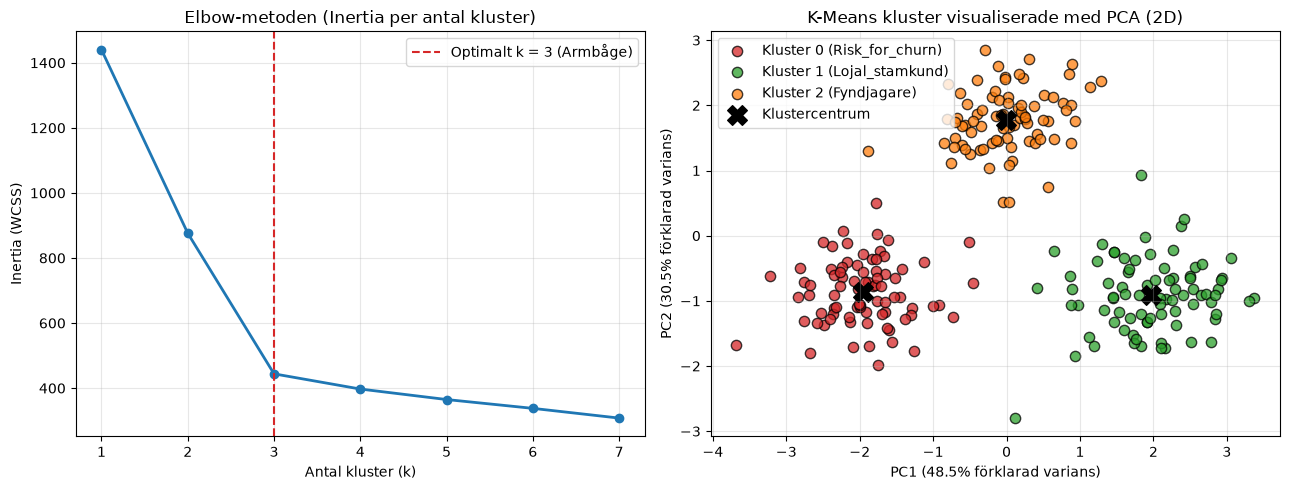

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Läs in och skala data
df = pd.read_csv("data_grupp_13.csv")
X = df.drop(columns=["target"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Elbow-metoden: beräkna Inertia (WCSS) för k = 1..8
inertias = []
k_range = range(1, 8)

for k in k_range:
  km = KMeans(n_clusters=k, n_init=10)
  km.fit(X_scaled)
  inertias.append(km.inertia_)

# 3. Träna K-Means med k=3 och reducera till 2 dimensioner med PCA
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

# 4. Rita ut båda graferna sida vid sida
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graf 1: Elbow-kurva
axes[0].plot(k_range, inertias, marker="o", linewidth=2, color="#1f77b4")
axes[0].axvline(
    x=3, color="#d62728", linestyle="--", label="Optimalt k = 3 (Armbåge)"
)
axes[0].set_title("Elbow-metoden (Inertia per antal kluster)")
axes[0].set_xlabel("Antal kluster (k)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_xticks(list(k_range))
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Graf 2: PCA 2D-kluster
colors = ["#d62728", "#2ca02c", "#ff7f0e"]
cluster_names = [
    "Kluster 0 (Risk_for_churn)",
    "Kluster 1 (Lojal_stamkund)",
    "Kluster 2 (Fyndjagare)",
]

for c in range(3):
  mask = clusters == c
  axes[1].scatter(
      X_pca[mask, 0],
      X_pca[mask, 1],
      c=colors[c],
      label=cluster_names[c],
      alpha=0.75,
      edgecolors="k",
      s=55,
  )

axes[1].scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="X",
    s=200,
    label="Klustercentrum",
)
var1, var2 = pca.explained_variance_ratio_ * 100
axes[1].set_title("K-Means kluster visualiserade med PCA (2D)")
axes[1].set_xlabel(f"PC1 ({var1:.1f}% förklarad varians)")
axes[1].set_ylabel(f"PC2 ({var2:.1f}% förklarad varians)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()